# 03 — Feature Engineering & Feature Selection

Target: **log(salary as share of cap)** in season *t*. Because contracts are signed before the season, the
"market value" model uses only information available **before** season *t* — previous-season performance, age,
experience, physical profile and draft pedigree. Same-season stats are kept aside for the surplus-value comparison.

In [1]:
import sys
sys.path.append("../src")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import build_features
import plotting as P

P.setup()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.0f}" if abs(x) >= 1000 else f"{x:,.3f}")

from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LassoCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
df = build_features(pd.read_csv("../data/processed/player_seasons.csv"))

## 1. Engineered features (`src/features.py`)

| Feature | Definition | Why |
|---|---|---|
| `salary_pct_cap`, `log_salary_pct_cap` | salary ÷ season salary cap; its log | removes cap inflation; log fixes the right skew (target) |
| `prev_*` | previous-season value of a stat (only if the seasons are consecutive) | contracts are priced on past production |
| `avg2_ws/vorp/bpm/mp_total` | mean of seasons *t−1* and *t−2* | smooths single-season noise; teams pay for track record |
| `*_per36` | per-game stat ÷ minutes × 36 | rate stats independent of role/minutes |
| rate-stat shrinkage | PER, TS%, USG%, WS/48, OBPM, DBPM, BPM, pts/36 → (x·MP + μ·250) / (MP + 250), μ = season's minutes-weighted mean (raw values kept as `*_raw`) | a 20-minute season with PER 60 is noise; shrinkage pulls it to league average while barely moving full-season values |
| `availability` | games played ÷ team games | durability; also adjusts for the shortened 2019-20/2020-21 seasons |
| `start_rate` | games started ÷ games | role proxy |
| `all_star`, `all_nba` (+ `prev_`) | parsed from the awards column | reputation premium |
| `age`, `age_sq` | age and its square | non-linear aging curve |
| `years_experience` | from team roster pages | service-time rules (minimum salaries scale with experience) |
| `pick_overall`, `first_round`, `undrafted` | from draft pages | draft pedigree |
| `rookie_scale` | 1st-round pick with ≤ 3 years experience | salary is set by the CBA rookie scale, not the market |
| `pos_group` | Guard / Forward / Center from listed position | position-specific pay |
| `shortened_season` | 2019-20 or 2020-21 | COVID-affected seasons |

## 2. Minimum-minutes filter

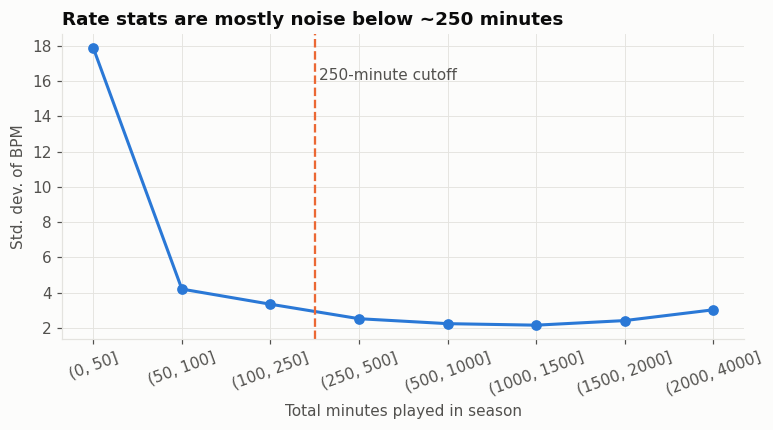

,n,sd_pts_per36,sd_ts_pct,sd_bpm
min_bin,,,,
"(0, 50]",315,11.464,0.260,17.871
"(50, 100]",191,4.511,0.137,4.200
"(100, 250]",426,4.433,0.103,3.342
"(250, 500]",548,3.723,0.070,2.521
"(500, 1000]",988,3.955,0.061,2.240
"(1000, 1500]",1011,4.018,0.053,2.155
"(1500, 2000]",943,4.514,0.047,2.414
"(2000, 4000]",997,5.307,0.041,3.026


In [3]:
paid = df[df.has_salary].copy()
bins = [0, 50, 100, 250, 500, 1000, 1500, 2000, 4000]
paid["min_bin"] = pd.cut(paid.mp_total, bins)
noise = paid.groupby("min_bin", observed=True).agg(n=("player_id", "size"), sd_pts_per36=("pts_per36_raw", "std"),
                                                    sd_ts_pct=("ts_pct_raw", "std"), sd_bpm=("bpm_raw", "std"))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(len(noise)), noise.sd_bpm, color=P.BLUE, marker="o", markersize=6)
ax.set_xticks(range(len(noise)), [str(i) for i in noise.index], rotation=20)
ax.axvline(2.5, color=P.ORANGE, linewidth=1.5, linestyle="--")
ax.annotate("250-minute cutoff", (2.55, noise.sd_bpm.max() * 0.9), color=P.TEXT_2)
ax.set_xlabel("Total minutes played in season"); ax.set_ylabel("Std. dev. of BPM")
ax.set_title("Rate stats are mostly noise below ~250 minutes")
P.save(fig, "fe_minutes_noise")
plt.show()
noise

Below 250 minutes (≈ 3 games' worth of a starter's minutes), rate stats like BPM have several times the spread they
have for regular rotation players, so those player-seasons are excluded from the modeling sample. They are mostly
two-way, 10-day and end-of-bench players paid near the minimum, plus injured players (see EDA §7).

## 3. Segmenting out rookie-scale contracts

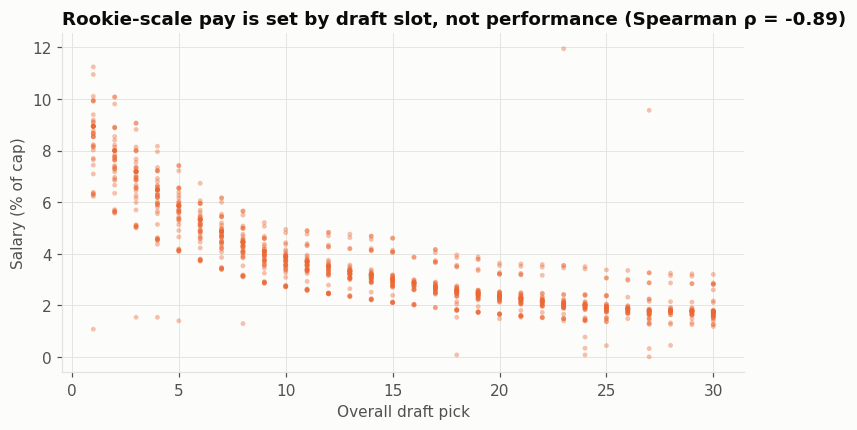

rookie-scale player-seasons: 1,102; corr with same-season VORP: 0.19


In [4]:
ms = df[df.modeling_sample == 1].copy()
rs = ms[ms.rookie_scale == 1]
rho = rs.pick_overall.corr(rs.salary_pct_cap, method="spearman")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(rs.pick_overall, rs.salary_pct_cap * 100, s=10, alpha=0.4, color=P.ORANGE, edgecolors="none")
ax.set_xlabel("Overall draft pick"); ax.set_ylabel("Salary (% of cap)")
ax.set_title(f"Rookie-scale pay is set by draft slot, not performance (Spearman ρ = {rho:.2f})")
P.save(fig, "fe_rookie_scale")
plt.show()
print(f"rookie-scale player-seasons: {len(rs):,}; corr with same-season VORP: {rs.vorp.corr(rs.salary_pct_cap, method='spearman'):.2f}")

Rookie-scale salaries are a near-deterministic function of draft slot (set by the collective bargaining agreement),
so including them in a "what does the market pay for" model would teach it the CBA table instead of market behavior.
**Decision:** the market-value model is fit on **non-rookie-scale** contracts with a previous season of data. Rookie-scale
players get a separate, simple slot-based baseline, and their surplus value is measured against it.

## 4. Candidate features for the market-value model

In [5]:
market = ms[(ms.rookie_scale == 0) & (ms.has_prev_season == 1)].copy()
for c in ["ws", "vorp", "bpm", "mp_total"]:
    market[f"avg2_{c}"] = market[f"avg2_{c}"].fillna(market[f"prev_{c}"])
market["pick_filled"] = market.pick_overall.fillna(61)
market = pd.concat([market, pd.get_dummies(market.pos_group, prefix="pos", dtype=int)], axis=1)
market["prev_pts_per36"] = market.prev_pts_per36.fillna(market.prev_pts_per36.median())
market["prev_ts_pct"] = market.prev_ts_pct.fillna(market.prev_ts_pct.median())

TARGET = "log_salary_pct_cap"
candidates = [
    "prev_pts", "prev_trb", "prev_ast", "prev_mp_per_g", "prev_g", "prev_gs", "prev_mp_total",
    "prev_per", "prev_ts_pct", "prev_usg_pct", "prev_ws", "prev_ws_per_48", "prev_obpm", "prev_dbpm",
    "prev_bpm", "prev_vorp", "prev_availability", "prev_pts_per36", "prev_all_star", "prev_all_nba",
    "avg2_ws", "avg2_vorp", "avg2_bpm", "avg2_mp_total",
    "age", "age_sq", "years_experience", "height_in", "weight", "pick_filled", "undrafted", "first_round",
    "pos_Guard", "pos_Forward", "pos_Center", "shortened_season",
]
market = market.dropna(subset=candidates + [TARGET])
print(f"Market-value sample: {len(market):,} player-seasons, {market.player_id.nunique():,} players, {len(candidates)} candidate features")
market[candidates].describe().T[["mean", "std", "min", "max"]]

Market-value sample: 2,833 player-seasons, 755 players, 36 candidate features


,mean,std,min,max
prev_pts,11.008,6.513,0.000,36.100
prev_trb,4.330,2.526,0.000,16.000
prev_ast,2.455,1.979,0.000,11.700
prev_mp_per_g,23.448,8.180,2.000,38.100
prev_g,58.097,19.127,1.000,84.000
prev_gs,31.703,28.316,0.000,83.000
prev_mp_total,"1,435",733.418,2.000,"3,125"
prev_per,15.098,3.761,6.457,31.168
prev_ts_pct,0.569,0.041,0.444,0.733
prev_usg_pct,19.550,4.646,8.042,39.914


**Time-based split** (prevents leaking future salary information into feature selection):
train = 2016-17 → 2022-23, validation = 2023-24, **test = 2024-25 and 2025-26 (held out, not touched here)**.
All feature-selection statistics below are computed on the **training seasons only**.

In [6]:
market["split"] = np.select([market.season <= 2023, market.season == 2024], ["train", "valid"], "test")
train, valid = market[market.split == "train"], market[market.split == "valid"]
market.split.value_counts().reindex(["train", "valid", "test"])

split
train    1945
valid     290
test      598
Name: count, dtype: int64

## 5. Filter methods: correlation and mutual information

In [7]:
spearman = train[candidates].corrwith(train[TARGET], method="spearman").fillna(0)
mi = pd.Series(mutual_info_regression(train[candidates], train[TARGET], random_state=0), index=candidates)
filt = pd.DataFrame({"spearman": spearman, "abs_spearman": spearman.abs(), "mutual_info": mi}).sort_values("mutual_info", ascending=False)
filt

,spearman,abs_spearman,mutual_info
years_experience,0.460,0.460,0.571
prev_mp_per_g,0.752,0.752,0.466
prev_pts,0.737,0.737,0.444
avg2_vorp,0.715,0.715,0.443
pick_filled,-0.509,0.509,0.420
avg2_ws,0.725,0.725,0.400
avg2_mp_total,0.698,0.698,0.370
prev_vorp,0.651,0.651,0.355
prev_ws,0.643,0.643,0.325
avg2_bpm,0.604,0.604,0.301


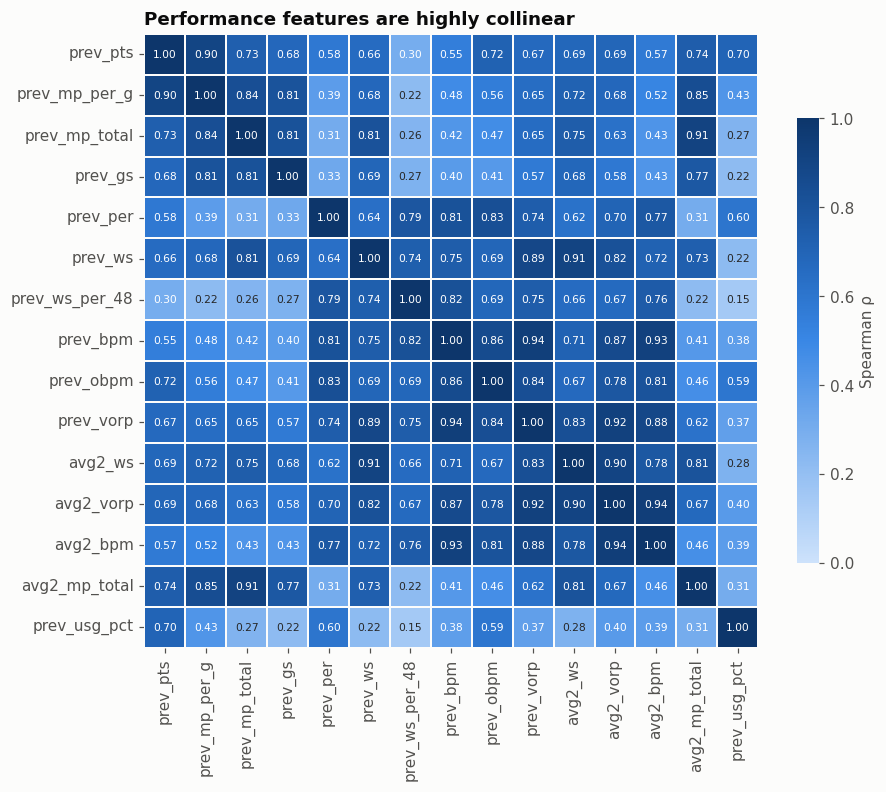

In [8]:
perf = ["prev_pts", "prev_mp_per_g", "prev_mp_total", "prev_gs", "prev_per", "prev_ws", "prev_ws_per_48",
        "prev_bpm", "prev_obpm", "prev_vorp", "avg2_ws", "avg2_vorp", "avg2_bpm", "avg2_mp_total", "prev_usg_pct"]
fig, ax = plt.subplots(figsize=(9, 7.5))
cm = train[perf].corr(method="spearman")
sns.heatmap(cm, cmap=P.SEQ, vmin=0, vmax=1, square=True, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=1, linecolor=P.SURFACE, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Performance features are highly collinear")
ax.grid(False)
P.save(fig, "fe_collinearity_heatmap")
plt.show()

## 6. Multicollinearity pruning (VIF)

Several advanced metrics are built from each other — BPM is exactly OBPM + DBPM, VORP is a function of BPM and
minutes, and WS is OWS + DWS — so some VIFs are infinite. We iteratively drop the feature with the highest VIF until
all are ≤ 10 (age is protected so the aging effect stays interpretable; its square goes instead).

In [9]:
import warnings

def vif_table(X):
    X = X.loc[:, X.std() > 0]
    Xs = (X - X.mean()) / X.std()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # perfectly collinear columns give VIF = inf
        return pd.Series([variance_inflation_factor(Xs.values, i) for i in range(Xs.shape[1])], index=X.columns)

numeric = [c for c in candidates if c not in ("pos_Guard", "pos_Forward", "pos_Center")] + ["pos_Guard", "pos_Center"]
kept, dropped = list(numeric), []
protected = {"age"}            # keep age; drop its square instead if they collide
while True:
    v = vif_table(train[kept])
    v_drop = v.drop(labels=[c for c in protected if c in v.index])
    if v_drop.max() <= 10:
        break
    worst = v_drop.idxmax()
    dropped.append((worst, round(v_drop.max(), 1)))
    kept.remove(worst)
print("Dropped for VIF > 10 (in order):", dropped)
vif_table(train[kept]).sort_values(ascending=False).to_frame("VIF")

Dropped for VIF > 10 (in order): [('prev_bpm', 3124.1), ('age_sq', 180.3), ('prev_ws', 137.8), ('avg2_vorp', 99.0), ('prev_pts_per36', 94.0), ('prev_pts', 62.9), ('prev_obpm', 47.5), ('prev_g', 43.0), ('prev_mp_total', 31.3), ('prev_per', 27.4), ('avg2_ws', 18.9), ('prev_vorp', 12.8)]


,VIF
pick_filled,9.288
years_experience,8.124
prev_mp_per_g,7.923
avg2_bpm,7.576
prev_ws_per_48,6.976
avg2_mp_total,6.910
age,6.770
first_round,5.605
height_in,4.836
prev_trb,4.117


## 7. Embedded / wrapper methods: Lasso and gradient-boosting permutation importance

In [10]:
# Folds grouped by season so a season's players never sit in both the fitting and scoring folds.
season_folds = list(GroupKFold(n_splits=5).split(train, groups=train.season))
lasso = make_pipeline(StandardScaler(), LassoCV(cv=season_folds, random_state=0, max_iter=20000))
lasso.fit(train[candidates], train[TARGET])
coefs = pd.Series(lasso[-1].coef_, index=candidates)
print(f"LassoCV alpha = {lasso[-1].alpha_:.4f}; non-zero coefficients: {(coefs != 0).sum()} of {len(candidates)}")
coefs[coefs != 0].sort_values(key=np.abs, ascending=False).to_frame("std_coef")

LassoCV alpha = 0.0009; non-zero coefficients: 32 of 36


,std_coef
age_sq,-1.132
age,1.068
avg2_vorp,-0.451
avg2_bpm,0.451
prev_mp_per_g,0.320
prev_per,-0.293
avg2_mp_total,0.245
avg2_ws,0.237
prev_pts,0.236
prev_usg_pct,0.209


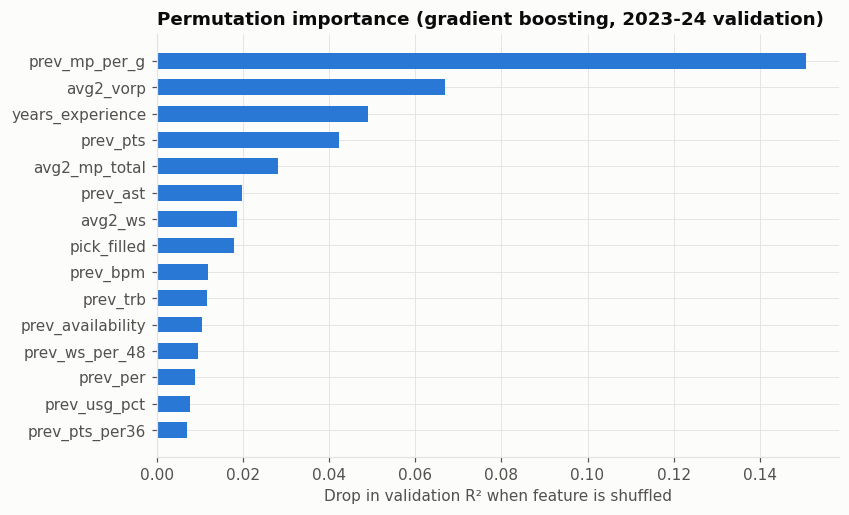

In [11]:
gbr = GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0)
gbr.fit(train[candidates], train[TARGET])
perm = permutation_importance(gbr, valid[candidates], valid[TARGET], n_repeats=15, random_state=0, scoring="r2")
perm_imp = pd.Series(perm.importances_mean, index=candidates).sort_values(ascending=False)

top = perm_imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(len(top)), top.values, height=0.6, color=P.BLUE)
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel("Drop in validation R² when feature is shuffled")
ax.set_title("Permutation importance (gradient boosting, 2023-24 validation)")
P.save(fig, "fe_permutation_importance")
plt.show()

## 8. Consolidated selection

In [12]:
votes = pd.DataFrame(index=candidates)
votes["spearman |ρ| ≥ 0.30"] = filt.abs_spearman.reindex(candidates) >= 0.30
votes["MI top 15"] = votes.index.isin(filt.mutual_info.nlargest(15).index)
votes["survives VIF"] = votes.index.isin(kept)
votes["Lasso ≠ 0"] = coefs.reindex(candidates) != 0
votes["perm. top 15"] = votes.index.isin(perm_imp.nlargest(15).index)
votes["votes"] = votes.sum(axis=1)
votes = votes.sort_values("votes", ascending=False)
votes.style.format({c: (lambda b: "✓" if b else "") for c in votes.columns if c != "votes"})

,spearman |ρ| ≥ 0.30,MI top 15,survives VIF,Lasso ≠ 0,perm. top 15,votes
prev_mp_per_g,✓,✓,✓,✓,✓,5
pick_filled,✓,✓,✓,✓,✓,5
avg2_mp_total,✓,✓,✓,✓,✓,5
prev_trb,✓,✓,✓,✓,✓,5
years_experience,✓,✓,✓,✓,✓,5
prev_pts,✓,✓,,✓,✓,4
prev_ws_per_48,✓,,✓,✓,✓,4
prev_availability,✓,,✓,✓,✓,4
avg2_ws,✓,✓,,✓,✓,4
avg2_vorp,✓,✓,,✓,✓,4


In [13]:
# Rule: keep features with >= 3 of 5 votes, then resolve remaining collinear pairs by keeping the
# one with higher permutation importance. Position dummies are kept as a group (one reference level).
selected = votes.index[votes.votes >= 3].tolist()
pairs = [(a, b) for i, a in enumerate(selected) for b in selected[i + 1:]
         if a.startswith(("prev_", "avg2_")) and b.startswith(("prev_", "avg2_"))
         and abs(train[a].corr(train[b], method="spearman")) > 0.9]
for a, b in pairs:
    if a in selected and b in selected:
        loser = a if perm_imp[a] < perm_imp[b] else b
        print(f"  ρ({a}, {b}) = {train[a].corr(train[b], method='spearman'):.2f} → drop {loser}")
        selected.remove(loser)
for p in ["pos_Guard", "pos_Center"]:
    if p not in selected:
        selected.append(p)
selected = [c for c in selected if c != "pos_Forward"]
print(f"{len(selected)} selected features:")
print(selected)

  ρ(prev_mp_per_g, prev_pts) = 0.90 → drop prev_pts
  ρ(avg2_mp_total, prev_mp_total) = 0.91 → drop prev_mp_total
  ρ(avg2_ws, avg2_vorp) = 0.90 → drop avg2_ws
  ρ(avg2_vorp, avg2_bpm) = 0.94 → drop avg2_bpm
  ρ(prev_usg_pct, prev_pts_per36) = 0.93 → drop prev_pts_per36
21 selected features:
['prev_mp_per_g', 'pick_filled', 'avg2_mp_total', 'prev_trb', 'years_experience', 'prev_ws_per_48', 'prev_availability', 'avg2_vorp', 'prev_usg_pct', 'prev_gs', 'prev_ast', 'weight', 'undrafted', 'first_round', 'prev_all_nba', 'prev_all_star', 'prev_obpm', 'prev_ws', 'prev_per', 'pos_Guard', 'pos_Center']


## 9. Readiness check — is there signal with the selected features?

In [14]:
def evaluate(model, feats):
    model.fit(train[feats], train[TARGET])
    pred = model.predict(valid[feats])
    pct_true, pct_pred = np.exp(valid[TARGET]) * 100, np.exp(pred) * 100
    return {"features": len(feats), "valid_R2_log": r2_score(valid[TARGET], pred),
            "valid_MAE_pct_cap": mean_absolute_error(pct_true, pct_pred)}

class MeanModel:
    def fit(self, X, y): self.m = y.mean(); return self
    def predict(self, X): return np.full(len(X), self.m)

readiness = pd.DataFrame({
    "Baseline: predict mean": evaluate(MeanModel(), selected),
    "Lasso, all candidates": evaluate(make_pipeline(StandardScaler(), LassoCV(cv=season_folds, max_iter=20000)), candidates),
    "Lasso, selected features": evaluate(make_pipeline(StandardScaler(), LassoCV(cv=season_folds, max_iter=20000)), selected),
    "Gradient boosting, selected features": evaluate(GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0), selected),
}).T.astype({"features": int})
readiness

,features,valid_R2_log,valid_MAE_pct_cap
Baseline: predict mean,21,-0.002,7.500
"Lasso, all candidates",36,0.644,3.522
"Lasso, selected features",21,0.630,3.599
"Gradient boosting, selected features",21,0.673,3.298


In [15]:
out_cols = ["season", "player_id", "player", "final_team", "split", "salary", "salary_cap", "salary_pct_cap", TARGET] + selected
market[out_cols].to_csv("../data/processed/model_table.csv", index=False)
rookie_cols = ["season", "player_id", "player", "final_team", "salary", "salary_pct_cap", "pick_overall", "years_experience", "vorp", "bpm", "ws"]
rs[rookie_cols].to_csv("../data/processed/rookie_scale_table.csv", index=False)
with open("../data/processed/selected_features.json", "w") as fh:
    json.dump({"target": TARGET, "features": selected, "candidates": candidates,
               "split": {"train": "2016-2023", "valid": "2024", "test": "2025-2026"}}, fh, indent=2)
print("Saved data/processed/model_table.csv", market[out_cols].shape)
print("Saved data/processed/rookie_scale_table.csv", rs[rookie_cols].shape)
print("Saved data/processed/selected_features.json")

Saved data/processed/model_table.csv (2833, 30)
Saved data/processed/rookie_scale_table.csv (1102, 11)
Saved data/processed/selected_features.json


## 10. Summary and next steps

- **Sample.** 4,488 player-seasons with a salary and ≥ 250 minutes. Excluding first-round rookie-scale contracts (pay set by draft slot, ρ(pick, pay) = −0.89) and requiring a previous season leaves a **market-value sample of 2,833 player-seasons (755 players)**: 1,945 train (2016-17 → 2022-23), 290 validation (2023-24), 598 test (2024-25, 2025-26, held out).
- **Engineering.** 36 candidate features: lagged and two-year-average production, minutes-weighted shrinkage of noisy rate stats, availability, awards, age/experience, physical profile, draft pedigree, position.
- **Selection.** Five methods (Spearman, mutual information, VIF pruning, Lasso, gradient-boosting permutation importance), a ≥ 3-of-5 vote, then removal of near-duplicate pairs (ρ > 0.9). **21 features selected.** Minutes and role (previous minutes per game, two-year minutes, games started), experience, draft pedigree, two-year VORP, and efficiency (WS/48, OBPM) carry the signal. Points per game drops out because, once minutes are known, it is almost a duplicate of them (ρ = 0.90): the market pays for *role* first. Age is represented through experience (ρ = 0.85).
- **Readiness.** On the 2023-24 validation season, gradient boosting with the 21 selected features explains 67% of the variance in log salary share (Lasso: 63%), with a mean absolute error of 3.3 percentage points of cap (≈ &#36;4.5M at the 2023-24 cap) vs 7.5 points (≈ &#36;10.2M) for a predict-the-mean baseline. Dropping 15 features cost almost nothing (Lasso R² 0.64 → 0.63), so the reduced set is ready for model training.

**Next phase — modeling plan**
1. **Market-value model:** regularized linear regression (interpretable "price" of each stat) vs. gradient boosting /
   random forest (non-linear), tuned with season-grouped cross-validation on 2016-17 → 2023-24, final evaluation on the
   held-out 2024-25 and 2025-26 seasons.
2. **Surplus value:** for each player-season, actual pay minus model-predicted pay (and production-based "deserved"
   pay using same-season stats); rookie-scale players compared against a draft-slot baseline.
3. **Team-level question:** do teams with higher total surplus value win more games, controlling for payroll?
4. **Deliverable:** a ranked over/under-paid list per season plus a small lookup tool (player → predicted vs. actual pay).